<a href="https://colab.research.google.com/github/000alan000/Google-Colab/blob/main/Alumno_ClasificacionSpotifyMLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación del género musical con una red neuronal multicapa (Spotify Dataset)

En este ejercicio utilizaremos una red neuronal multicapa para resolver un problema de clasificación multiclase


Queremos resolver:

> **¿Podemos identificar el género musical de una canción a partir de sus características de audio?**

# Conjunto Datos

Utilizaremos algunas de las características musicales proporcionadas por Spotify y construiremos una red neuronal capaz de clasificar una canción dentro de uno de cinco géneros:

* Pop
* Rock
* Jazz
* Classical
* Hip-hop

La base de datos de Spotify, contiene información de miles de canciones disponibles en la plataforma Spotify.

Cada canción incluyen atributos cuantitativos como

* Danceability (bailabilidad),

* Energy (nivel de energía),

* Loudness (volumen promedio en decibelios),

* Speechiness (porcentaje de contenido hablado),

* Acousticness (nivel de acústica),

* Instrumentalness (nivel instrumental de la canción),

* Valence (positividad emocional),

* Tempo (ritmo de una canción, se mide en beats por minuto),

* Popularity (nivel de popularidad de la canción),

* Duration_ms (duración en milisegundos)

Entre otros.

Cargamos el dataset

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/mevangelista-alvarado/datasets/refs/heads/main/spotify_songs.csv"
df = pd.read_csv(url)

Visualizamos el dataframe

In [2]:
df

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


In [3]:
df.shape

(114000, 21)

# Conjunto de entrenamiento y test

## Explorar los datos

Numero de filas y columnas

In [4]:
df.shape


(114000, 21)

Observamos informacion del dataframe

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

También podemos observar algunas estadísticas:


In [6]:
df.describe()


,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [7]:
df.describe(include="object")

,track_id,artists,album_name,track_name,track_genre
count,114000,113999,113999,113999,114000
unique,89741,31437,46589,73608,114
top,6S3JlDAGk3uu3NtZbPnuhS,The Beatles,Alternative Christmas 2022,Run Rudolph Run,acoustic
freq,9,279,195,151,1000


## Exploramos la etiqueta (label)

La variable que queremos predecir será:

```text
track_genre
```

Podemos observar los géneros disponibles:



In [8]:
df['track_genre'].unique()

array(['acoustic', 'afrobeat', 'alt-rock', 'alternative', 'ambient',
       'anime', 'black-metal', 'bluegrass', 'blues', 'brazil',
       'breakbeat', 'british', 'cantopop', 'chicago-house', 'children',
       'chill', 'classical', 'club', 'comedy', 'country', 'dance',
       'dancehall', 'death-metal', 'deep-house', 'detroit-techno',
       'disco', 'disney', 'drum-and-bass', 'dub', 'dubstep', 'edm',
       'electro', 'electronic', 'emo', 'folk', 'forro', 'french', 'funk',
       'garage', 'german', 'gospel', 'goth', 'grindcore', 'groove',
       'grunge', 'guitar', 'happy', 'hard-rock', 'hardcore', 'hardstyle',
       'heavy-metal', 'hip-hop', 'honky-tonk', 'house', 'idm', 'indian',
       'indie-pop', 'indie', 'industrial', 'iranian', 'j-dance', 'j-idol',
       'j-pop', 'j-rock', 'jazz', 'k-pop', 'kids', 'latin', 'latino',
       'malay', 'mandopop', 'metal', 'metalcore', 'minimal-techno', 'mpb',
       'new-age', 'opera', 'pagode', 'party', 'piano', 'pop-film', 'pop',
       'pow

Y contar cuántas canciones existen para cada género:


In [9]:
df['track_genre'].value_counts()


,count
track_genre,
acoustic,1000
afrobeat,1000
alt-rock,1000
alternative,1000
ambient,1000
...,...
techno,1000
trance,1000
trip-hop,1000


Notamos que nuestro conjunto de datos contiene muchos géneros diferentes.

Para este ejercicio utilizaremos únicamente:


In [10]:
generos = [
    'pop',
    'rock',
    'jazz',
    'classical',
    'hip-hop'
]


Ahora filtramos el DataFrame:



In [11]:
df = df[df['track_genre'].isin(generos)].copy()


In [12]:
df.shape

(5000, 21)

Podemos comprobar el resultado:



In [13]:
df['track_genre'].value_counts()


,count
track_genre,
classical,1000
hip-hop,1000
jazz,1000
pop,1000
rock,1000


In [14]:
df.shape

(5000, 21)

## Exploramos el input

Ahora necesitamos decidir qué información utilizaremos para intentar identificar el género.

Utilizaremos:


In [15]:
# @title
features = [
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]


Estas variables representan diferentes características de la canción.

Podemos observarlas:



In [16]:
df[features].head()


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
16000,0.643,0.268,-15.073,0.0900,0.593,0.000002,0.316,0.620,143.813
16001,0.484,0.898,-4.132,0.1640,0.365,0.000000,0.091,0.680,91.975
16002,0.608,0.638,-6.008,0.0292,0.581,0.017200,0.448,0.439,140.109
16003,0.695,0.293,-16.278,0.0431,0.596,0.015800,0.132,0.637,143.804
16004,0.583,0.308,-18.303,0.0465,0.581,0.010600,0.257,0.241,118.226


Algunas de estas características representan:

| Variable           | Descripción                                |
| ------------------ | ------------------------------------------ |
| `danceability`     | Qué tan adecuada es la canción para bailar |
| `energy`           | Nivel de energía                           |
| `loudness`         | Volumen promedio                           |
| `speechiness`      | Presencia de palabras habladas             |
| `acousticness`     | Probabilidad de que sea acústica           |
| `instrumentalness` | Probabilidad de que sea instrumental       |
| `liveness`         | Probabilidad de una interpretación en vivo |
| `valence`          | Positividad o carácter emocional           |
| `tempo`            | Velocidad en BPM                           |

Estas serán las variables de entrada de nuestra red neuronal.

## Construir X e y


Construiremos `X` utilizando nuestras características musicales:



In [17]:
X = df[features]


In [18]:
X.shape

(5000, 9)

Y utilizaremos `track_genre` como variable objetivo:



In [19]:
import pandas as pd

y = df['track_genre']
# One-hot encoding
Y = pd.get_dummies(y).values


In [20]:
y

,track_genre
16000,classical
16001,classical
16002,classical
16003,classical
16004,classical
...,...
91995,rock
91996,rock
91997,rock
91998,rock


In [21]:
Y

array([[ True, False, False, False, False],
       [ True, False, False, False, False],
       [ True, False, False, False, False],
       ...,
       [False, False, False, False,  True],
       [False, False, False, False,  True],
       [False, False, False, False,  True]])

In [22]:
pd.get_dummies(y).columns

Index(['classical', 'hip-hop', 'jazz', 'pop', 'rock'], dtype='object')

Podemos comprobar las dimensiones:


In [23]:
print("X:", X.shape)
print("y:", Y.shape)


X: (5000, 9)
y: (5000, 5)


Conceptualmente tenemos:

```text
Características musicales
          ↓
          X
          ↓
     Red neuronal
          ↓
          Y
          ↓
     Género musical
```

## Dividir los datos


Utilizaremos el 80 % para entrenar y el 20 % para evaluar.


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)


El parámetro `stratify=y_encoded` intenta conservar la proporción de cada género tanto en entrenamiento como en prueba.

In [25]:
print(X_train.shape)
print(X_test.shape)


(4000, 9)
(1000, 9)


Normalizar las características

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


Recuerde que `StandardScaler`, transforma las variables para que tengan aproximadamente:
* media = 0
* desviación estándar = 1

# Modelo (Red Neuronal)

In [27]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

modelo = Sequential([
    Dense(64, input_shape=(X_train.shape[1],), activation='relu'),
    Dense(32, activation='relu'),
    Dense(5, activation='softmax'),
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


La función `softmax` convierte la salida en probabilidades.

Por ejemplo:

```text
classical → 0.02
hip-hop   → 0.15
jazz      → 0.08
pop       → 0.65
rock      → 0.10
```

La red considera que `pop` es la clase más probable porque tiene la probabilidad más alta.

In [28]:
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,885 (11.27 KB)

 Trainable params: 2,885 (11.27 KB)

 Non-trainable params: 0 (0.00 B)

Esto nos permite conocer:

* número de capas,
* número de neuronas,
* número de parámetros entrenables.

Optimizador

In [29]:
from tensorflow.keras.optimizers import Adam

# Tasa de aprendizaje deseada
learning_rate = 0.01
adam_optimizer = Adam(learning_rate=learning_rate)


In [30]:
modelo.compile(
    optimizer=adam_optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenamiento

In [31]:
history = modelo.fit(
    X_train, y_train,
    epochs=10, batch_size=2,
    validation_data=(X_test, y_test)
)


Epoch 1/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.5995 - loss: 0.9731 - val_accuracy: 0.6220 - val_loss: 0.9838
Epoch 2/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.6288 - loss: 0.9162 - val_accuracy: 0.6190 - val_loss: 0.9622
Epoch 3/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6370 - loss: 0.9106 - val_accuracy: 0.6490 - val_loss: 0.8908
Epoch 4/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.6320 - loss: 0.9028 - val_accuracy: 0.6340 - val_loss: 0.9199
Epoch 5/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6475 - loss: 0.8846 - val_accuracy: 0.6330 - val_loss: 0.9046
Epoch 6/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6495 - loss: 0.8639 - val_accuracy: 0.6560 - val_loss: 0.9076
Epoch 7/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.6580 - loss: 0.8735 - val_accuracy: 0.6460 - val_loss: 0.9094
Epoch 8/10
2000/2000 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.6568 - loss: 0.8657

Visualizamos la función de pérdida

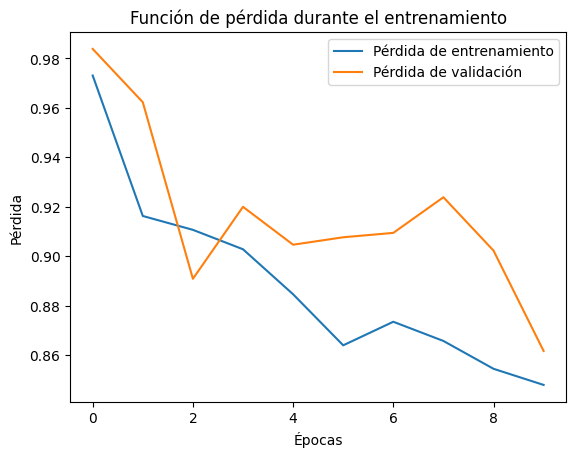

In [32]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Función de pérdida durante el entrenamiento')
plt.show()


Visualizamos el accuracy

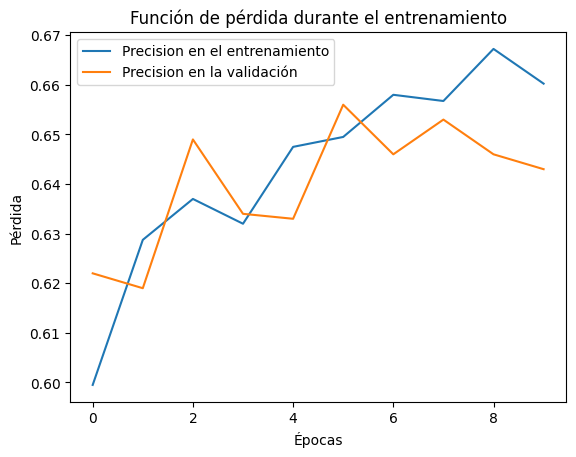

In [33]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Precision en el entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precision en la validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.title('Función de pérdida durante el entrenamiento')
plt.show()


# Evaluacion

In [34]:
loss, accuracy = modelo.evaluate(X_test, y_test)
print(f'Loss: {loss}, Accuracy: {accuracy}')


32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - accuracy: 0.6430 - loss: 0.8617
Loss: 0.8616541624069214, Accuracy: 0.6430000066757202


## Matriz de Confusión

In [35]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, recall_score

y_pred = modelo.predict(X_test)
# Convertir las predicciones a clases
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# Calcular la matriz de confusión
cm = confusion_matrix(y_test_classes, y_pred_classes)
# Calcular la sensibilidad
sensitivity = recall_score(y_test_classes, y_pred_classes, average=None)


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


Sensitivity (Recall) for each class:
Class 0: 0.74
Class 1: 0.795
Class 2: 0.76
Class 3: 0.25
Class 4: 0.67


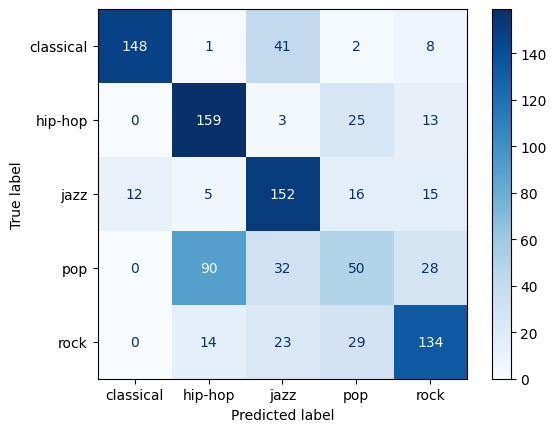

In [36]:
class_names = pd.get_dummies(y).columns.tolist()

# Visualizar la matriz de confusión como una imagen de colores
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap='Blues')

# Mostrar la sensibilidad (recall) para cada clase
print('Sensitivity (Recall) for each class:')
for i in range(5):
    print(f'Class {i}: {sensitivity[i]}')


# Prediccion

In [37]:
class_names = pd.get_dummies(y).columns.tolist()

predictions = modelo.predict(X_test)
# Obtener el índice de la clase predicha para cada punto de datos
predicted_classes = np.argmax(predictions, axis=1) # y_pred
# Obtenemos el índice de la clase real de y_test
actual_classes = np.argmax(y_test, axis=1) # y_real

comparison = pd.DataFrame({
  'Actual Class Index': actual_classes,
  'Predicted Class Index': predicted_classes
})
# Agregar columnas con los nombres reales y predichos de las flores utilizando iris.target_names
comparison['Actual Flower'] = [class_names[i] for i in actual_classes]
comparison['Predicted Flower'] = [class_names[i] for i in predicted_classes]
# Reordenar las columnas para una mejor visualización
comparison = comparison[['Actual Class Index', 'Actual Flower', 'Predicted Class Index', 'Predicted Flower']]
print(comparison.head(30))


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
    Actual Class Index Actual Flower  Predicted Class Index Predicted Flower
0                    3           pop                      1          hip-hop
1                    1       hip-hop                      1          hip-hop
2                    4          rock                      3              pop
3                    2          jazz                      2             jazz
4                    2          jazz                      2             jazz
5                    4          rock                      4             rock
6                    4          rock                      4             rock
7                    3           pop                      2             jazz
8                    4          rock                      3              pop
9                    2          jazz                      2             jazz
10                   2          jazz                      2             jazz
11                   3           pop

Predicción manual del género de una canción

In [38]:
class_names = pd.get_dummies(y).columns.tolist()

# Introducir los valores de una canción
danceability = 0.72
energy = 0.50
loudness = 4.0
speechiness = 0.03
acousticness = 0.5
instrumentalness = 0.3
liveness = 0.25
valence = 0.85
tempo = 100

# Crear un df
cancion_nueva = pd.DataFrame([{
    'danceability': danceability,
    'energy': energy,
    'loudness': loudness,
    'speechiness': speechiness,
    'acousticness': acousticness,
    'instrumentalness': instrumentalness,
    'liveness': liveness,
    'valence': valence,
    'tempo': tempo
}])

# Escalar los datos de entrada usando el mismo scaler que se usó para el entrenamiento
cancion_nueva_scaled = scaler.transform(
    cancion_nueva
)

# Realizar la predicción con el modelo
probabilidades = modelo.predict(
    cancion_nueva_scaled,
    verbose=0
)

# Obtener las probabilidades
probabilidades = probabilidades[0]
# np.argmax() encuentra la posición que contiene el valor más grande.
clase_predicha = np.argmax(probabilidades)
genero_predicho = class_names[clase_predicha]


# Obtener el nombre de la cancion
print(f"Género predicho: {genero_predicho}")

# Mostrar todas las probabilidades
print("\nProbabilidades por género:")
print("----------------------------------------")
for genero, probabilidad in zip(
    class_names,
    probabilidades
):
    print(
        f"{genero:10s}: {probabilidad:.2%}"
    )


Género predicho: jazz

Probabilidades por género:
----------------------------------------
classical : 4.65%
hip-hop   : 12.16%
jazz      : 35.73%
pop       : 24.49%
rock      : 22.97%
